# 01 - A tour of the fake dataset, and the SQL behind it

Runs on fake data only (`npm run fake:load`). Analysing real users needs a privacy policy and anonymisation first (spec 04).

This notebook answers: **what does the fake CineCircle look like, and can I get the learning-track
questions out of it with hand-written SQL?** It reads the rows `npm run fake:load` wrote to the
local Supabase (seed 7, 50 users, 300 titles, ~3,000 ratings) and nothing else: every query below
keeps only fake users (`@fake.cinecircle.local`) and fake titles (`tmdb_id >= FAKE_TMDB_BASE`), so
any real local account is invisible to it.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import sqlalchemy as sa

from cinecircle_analysis import frames
from cinecircle_analysis.fakedata import FAKE_DOMAIN, FAKE_TMDB_BASE
from cinecircle_analysis.load import assert_local
from cinecircle_api.db import act_as, make_engine
from cinecircle_api.settings import Settings

engine = make_engine(Settings().database_url)
assert_local(engine)  # raises before any query unless the database is on this machine

FAKE = {"pattern": f"%@{FAKE_DOMAIN}", "base": FAKE_TMDB_BASE}  # the fake-only filters, as params
BLUE, ORANGE, GREY = "#3b6fb6", "#d9822b", "#8a8a8a"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.figsize": (7, 4)})


def sql(query: str, **params) -> pd.DataFrame:
    """Run one hand-written, read-only query with the fake-only params always bound."""
    with engine.connect() as conn:
        return pd.read_sql_query(sa.text(query), conn, params={**FAKE, **params})


print("local database, fake-only filters:", FAKE["pattern"], "and tmdb_id >=", FAKE["base"])

local database, fake-only filters: %@fake.cinecircle.local and tmdb_id >= 2000000000


## 1. Shape of the data

`frames` is the same fake-only reader the evaluation uses. Counts first, then a few sanity checks
the generator promises (one rating per user and title, half-star steps, follows between fake
users only).

In [2]:
users, titles, posts, follows, wishlist, events = (
    pd.DataFrame(read(engine))
    for read in (frames.users, frames.titles, frames.posts, frames.follows,
                 frames.wishlist, frames.events)
)
shape = pd.Series(
    {"users": len(users), "titles": len(titles), "ratings (posts)": len(posts),
     "follows": len(follows), "wishlist items": len(wishlist), "events": len(events)},
    name="rows",
)
display(shape.to_frame())

assert not posts.duplicated(["author", "title"]).any()  # one rating per user and title
assert (posts.rating * 2 == (posts.rating * 2).round()).all()  # half steps
assert posts.rating.between(1, 10).all()
assert (follows.follower != follows.followee).all()
print("sanity checks pass; shared share of ratings:", round(posts.is_shared.mean(), 3),
      "| accepted share of follows:", round((follows.status == "accepted").mean(), 3))

,rows
users,50
titles,300
ratings (posts),3000
follows,401
wishlist items,1619
events,11519


sanity checks pass; shared share of ratings: 0.79 | accepted share of follows: 0.903


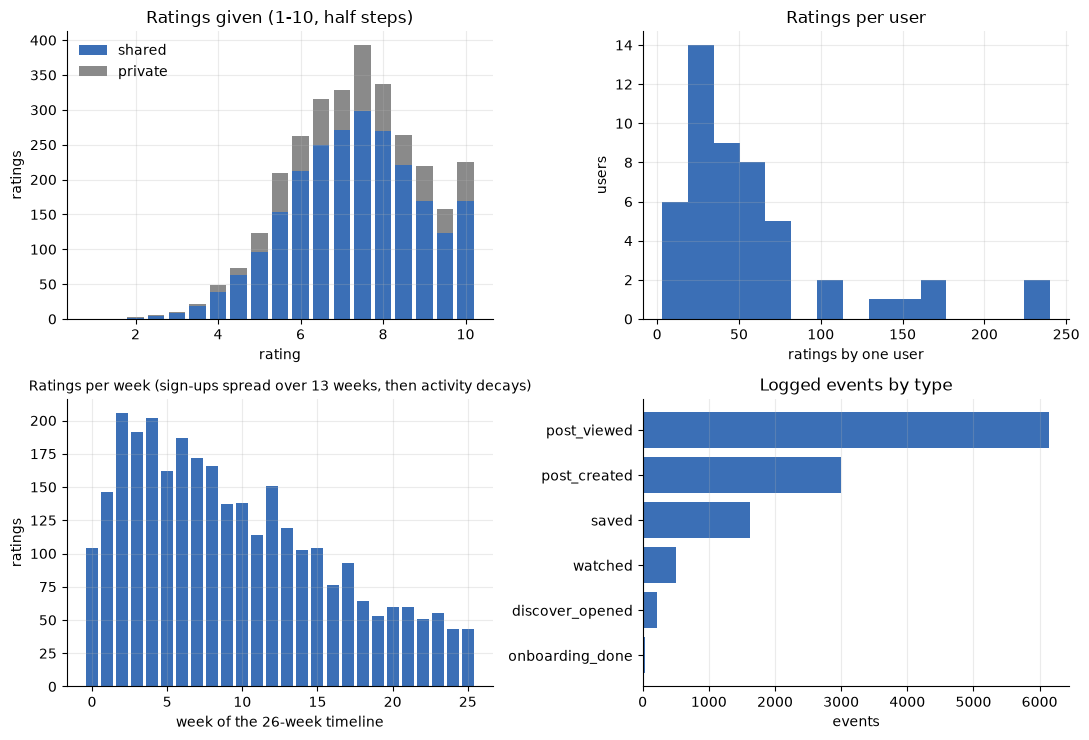

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))

ax = axes[0, 0]
steps = [x / 2 for x in range(2, 21)]
shared = posts[posts.is_shared].rating.value_counts().reindex(steps, fill_value=0)
private = posts[~posts.is_shared].rating.value_counts().reindex(steps, fill_value=0)
ax.bar(steps, shared, width=0.4, color=BLUE, label="shared")
ax.bar(steps, private, width=0.4, bottom=shared, color=GREY, label="private")
ax.set(title="Ratings given (1-10, half steps)", xlabel="rating", ylabel="ratings")
ax.legend(frameon=False)

ax = axes[0, 1]
per_user = posts.groupby("author").size()
ax.hist(per_user, bins=15, color=BLUE)
ax.set(title="Ratings per user", xlabel="ratings by one user", ylabel="users")

ax = axes[1, 0]
week = ((posts.created_at - posts.created_at.min()).dt.days // 7).value_counts().sort_index()
ax.bar(week.index, week.values, color=BLUE)
ax.set(title="Ratings per week (sign-ups spread over 13 weeks, then activity decays)",
       xlabel="week of the 26-week timeline", ylabel="ratings")
ax.title.set_fontsize(10)

ax = axes[1, 1]
by_type = events.event_type.value_counts().sort_values()
ax.barh(by_type.index, by_type.values, color=BLUE)
ax.set(title="Logged events by type", xlabel="events")
ax.grid(axis="y", alpha=0)

fig.tight_layout()
plt.show()

## 2. Learning-track SQL (hand-written, read-only)

Four of the learning-track questions from spec 04, as `sqlalchemy.text` against the live tables.
Every statement is restricted to fake users and fake titles through the bound `:pattern` and
`:base` parameters.

### 2.1 Which genres are most common in the title cache?

The spec's version uses `jsonb_array_elements` over TMDB's cached `genres` array. The fake titles
carry no TMDB payload (their `raw_tmdb` is just `{"fake": true}`), so the same question is
answered here through the `title_genres` join table instead.

,genre,titles
0,Adventure,44
1,Documentary,40
2,Thriller,40
3,History,39
4,Family,38
5,Mystery,36
6,Action,35
7,Animation,35


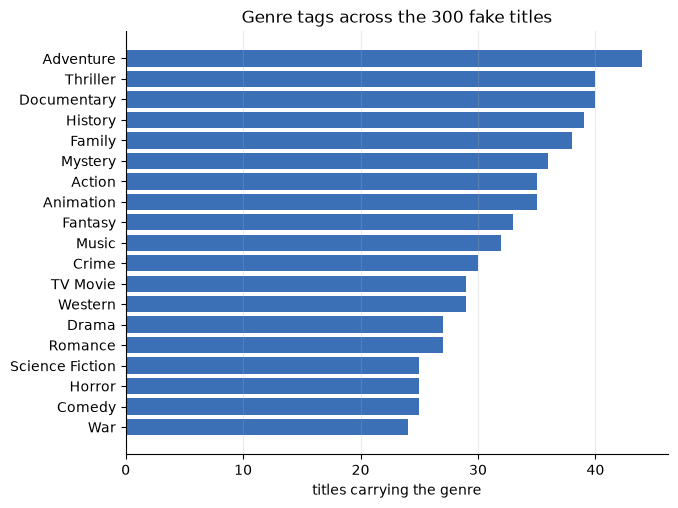

In [4]:
common_genres = sql("""
    SELECT g.name_en AS genre, count(*) AS titles
    FROM app.title_genres tg
    JOIN app.titles t ON t.id = tg.title_id AND t.tmdb_id >= :base
    JOIN app.genres g ON g.id = tg.genre_id
    GROUP BY g.name_en
    ORDER BY titles DESC, genre
""")
display(common_genres.head(8))

top = common_genres.sort_values("titles")
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top.genre, top.titles, color=BLUE)
ax.set(title="Genre tags across the 300 fake titles", xlabel="titles carrying the genre")
ax.grid(axis="y", alpha=0)
plt.show()

### 2.2 Average rating per user per month

`GROUP BY` user and month with `HAVING` to drop user-months with fewer than five ratings (a mean
of two ratings is noise). The thin lines are individual users, the thick one the mean of them:
the spread between lines is the generator's per-user harshness bias.

,username,month,ratings,avg_rating
0,fake_adi_23,2026-05-01,20,7.80
1,fake_alon_26,2026-05-01,11,8.09
2,fake_alon_26,2026-06-01,11,8.68
3,fake_alon_26,2026-07-01,7,8.07
4,fake_alon_26,2026-08-01,7,8.07
5,fake_amit_13,2026-06-01,20,7.93


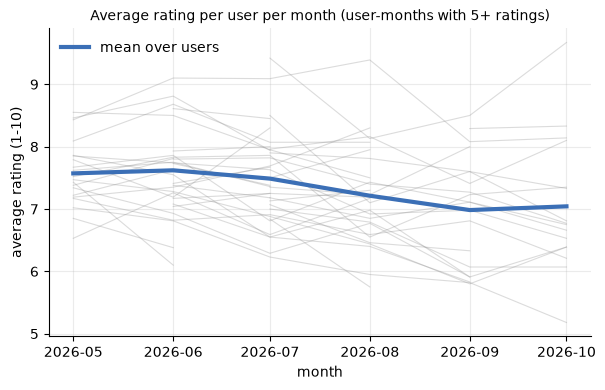

user-months kept: 158 | spread between users' monthly means (SD): 0.8


In [5]:
monthly = sql("""
    SELECT p.username,
           date_trunc('month', po.created_at)::date AS month,
           count(*) AS ratings,
           round(avg(po.rating), 2) AS avg_rating
    FROM app.posts po
    JOIN auth.users u ON u.id = po.author_id AND u.email LIKE :pattern
    JOIN app.profiles p ON p.id = po.author_id
    JOIN app.titles t ON t.id = po.title_id AND t.tmdb_id >= :base
    WHERE po.season_number = 0
    GROUP BY p.username, date_trunc('month', po.created_at)
    HAVING count(*) >= 5
    ORDER BY p.username, month
""")
monthly["avg_rating"] = monthly.avg_rating.astype(float)
display(monthly.head(6))

wide = monthly.pivot(index="month", columns="username", values="avg_rating")
fig, ax = plt.subplots()
ax.plot(wide.index, wide.values, color=GREY, alpha=0.3, linewidth=0.8)
ax.plot(wide.index, wide.mean(axis=1), color=BLUE, linewidth=3, label="mean over users")
ax.set(title="Average rating per user per month (user-months with 5+ ratings)",
       xlabel="month", ylabel="average rating (1-10)")
ax.title.set_fontsize(10)
ax.legend(frameon=False)
plt.show()
print("user-months kept:", len(monthly), "| spread between users' monthly means (SD):",
      round(monthly.avg_rating.std(), 2))

### 2.3 Accounts followed by people I follow, that I don't follow yet

A self-join on `follows`: take one fake user's accepted followees, then everyone *they* follow,
minus me and minus anyone I already follow or have a pending request to. The user is the fake
account with the most accepted followees, so there is something to show. Candidates are ranked by
how many of my followees follow them.

In [6]:
me = sql("""
    SELECT u.email, p.username, count(*) AS followees
    FROM app.follows f
    JOIN auth.users u ON u.id = f.follower_id AND u.email LIKE :pattern
    JOIN app.profiles p ON p.id = u.id
    WHERE f.status = 'accepted'
    GROUP BY u.email, p.username
    ORDER BY followees DESC, u.email
    LIMIT 1
""").iloc[0]
print(f"me = {me.username} ({me.followees} accepted followees)")

suggestions = sql("""
    WITH me AS (SELECT id FROM auth.users WHERE email = :me AND email LIKE :pattern),
         my_followees AS (
             SELECT followee_id FROM app.follows
             WHERE follower_id = (SELECT id FROM me) AND status = 'accepted')
    SELECT p.username, count(*) AS followed_by_my_followees
    FROM app.follows f
    JOIN my_followees mf ON mf.followee_id = f.follower_id
    JOIN auth.users cu ON cu.id = f.followee_id AND cu.email LIKE :pattern
    JOIN app.profiles p ON p.id = f.followee_id
    WHERE f.status = 'accepted'
      AND f.followee_id <> (SELECT id FROM me)
      AND NOT EXISTS (SELECT 1 FROM app.follows own
                      WHERE own.follower_id = (SELECT id FROM me)
                        AND own.followee_id = f.followee_id)
    GROUP BY p.username
    ORDER BY followed_by_my_followees DESC, p.username
    LIMIT 8
""", me=me.email)
display(suggestions)

me = fake_liat_30 (15 accepted followees)


,username,followed_by_my_followees
0,fake_amit_13,5
1,fake_gal_32,5
2,fake_daniel_16,4
3,fake_roni_14,4
4,fake_adi_23,3
5,fake_alon_26,3
6,fake_daniel_46,3
7,fake_guy_24,3


### 2.4 Rank each user's genres by affinity

A CTE builds each user's average rating per genre (at least three ratings, to keep it honest) and
`RANK() OVER (PARTITION BY user ORDER BY avg DESC)` numbers them. As a check on the generator: for
users who did onboarding, how often is their top-ranked genre one of the three they picked?

In [7]:
affinity = sql("""
    WITH rated AS (
        SELECT po.author_id, tg.genre_id, po.rating
        FROM app.posts po
        JOIN auth.users u ON u.id = po.author_id AND u.email LIKE :pattern
        JOIN app.titles t ON t.id = po.title_id AND t.tmdb_id >= :base
        JOIN app.title_genres tg ON tg.title_id = po.title_id
        WHERE po.season_number = 0),
    per_genre AS (
        SELECT author_id, genre_id, count(*) AS n, avg(rating) AS avg_rating
        FROM rated GROUP BY author_id, genre_id HAVING count(*) >= 3),
    ranked AS (
        SELECT *, RANK() OVER (PARTITION BY author_id
                               ORDER BY avg_rating DESC, n DESC) AS rnk
        FROM per_genre)
    SELECT p.username, r.genre_id, g.name_en AS genre, r.n,
           round(r.avg_rating, 2) AS avg_rating, r.rnk
    FROM ranked r
    JOIN app.profiles p ON p.id = r.author_id
    JOIN app.genres g ON g.id = r.genre_id
    WHERE r.rnk <= 3
    ORDER BY p.username, r.rnk
""")
display(affinity.head(9))

picks = users.set_index("username").picks
top1 = affinity[affinity.rnk == 1]
onboarded = top1[top1.username.map(lambda name: len(picks[name]) > 0)]
hit = onboarded.apply(lambda r: r.genre_id in picks[r.username], axis=1)
print(f"users with a ranked genre: {top1.username.nunique()}, of whom onboarded: "
      f"{onboarded.username.nunique()}; top genre is one of their 3 picks for "
      f"{hit.mean():.0%} (roughly {3 / 19:.0%} by chance: 3/19 under a uniform draw)")

,username,genre_id,genre,n,avg_rating,rnk
0,fake_adi_23,10402,Music,4,9.00,1
1,fake_adi_23,16,Animation,6,8.75,2
2,fake_adi_23,10751,Family,7,8.50,3
3,fake_alon_26,10752,War,3,9.67,1
4,fake_alon_26,12,Adventure,14,8.93,2
5,fake_alon_26,9648,Mystery,3,8.67,3
6,fake_amit_13,16,Animation,6,9.08,1
7,fake_amit_13,12,Adventure,8,8.81,2
8,fake_amit_13,10751,Family,13,8.42,3


users with a ranked genre: 49, of whom onboarded: 37; top genre is one of their 3 picks for 41% (roughly 16% by chance: 3/19 under a uniform draw)


## 3. Proving row-level security in SQL

Spec 04 asks: *prove, in SQL, that Noa can't read Gal's posts.* Here it is with fake users, so no
test account is touched. Pick a fake author **B** who has both shared and private ratings, then
look at B's posts as four different people: B, an approved follower, someone with a still-pending
request, and a stranger with no follow row either way. Each look is a transaction that
`act_as` (the same function the API uses) switches to `authenticated` with that person's id in the
JWT claims, so Postgres applies the `posts_read` policy; the transaction is rolled back after, so
nothing persists. The expected answer is in the assertions.

In [8]:
uid = users.set_index("n").id
by_author = posts.groupby("author").agg(total=("rating", "size"), shared=("is_shared", "sum"))
by_author["private"] = by_author.total - by_author.shared
accepted = follows[follows.status == "accepted"]
pending = follows[follows.status == "pending"]
knows = set(zip(follows.follower, follows.followee)) | set(zip(follows.followee, follows.follower))

# B: a fake author with an approved follower, a pending requester, and both private and shared posts
b = next(
    n for n in by_author[by_author.private >= 3].sort_values("total", ascending=False).index
    if n in set(accepted.followee) and n in set(pending.followee)
)
approved = int(accepted[accepted.followee == b].follower.min())
requester = int(pending[pending.followee == b].follower.min())
stranger = next(n for n in users.n if n != b and (n, b) not in knows)
truth = by_author.loc[b]
print(f"B = fake{b:02d}: {truth.total} ratings, {truth.shared} shared, {truth.private} private")


def what_the_viewer_sees(viewer_n: int) -> dict:
    claims = {"sub": str(uid[viewer_n]), "role": "authenticated"}
    with engine.connect() as conn:
        try:
            act_as(conn, claims)  # SET LOCAL ROLE authenticated + the JWT claims
            row = conn.execute(sa.text(
                "SELECT current_user AS role, count(*) AS sees_total,"
                " count(*) FILTER (WHERE is_shared) AS sees_shared"
                " FROM app.posts WHERE author_id = :b"), {"b": uid[b]}).one()
        finally:
            conn.rollback()  # nothing persists; the role switch ends with the transaction
    return {"viewer": f"fake{viewer_n:02d}", **row._asdict()}


proof = pd.DataFrame([
    {"relationship to B": "B themself", **what_the_viewer_sees(b)},
    {"relationship to B": "approved follower", **what_the_viewer_sees(approved)},
    {"relationship to B": "pending request", **what_the_viewer_sees(requester)},
    {"relationship to B": "stranger", **what_the_viewer_sees(stranger)},
]).set_index("relationship to B")
display(proof)

assert list(proof.role.unique()) == ["authenticated"]
assert proof.loc["B themself", "sees_total"] == truth.total  # the owner sees everything
assert proof.loc["approved follower", "sees_total"] == truth.shared  # shared only, no private
assert proof.loc["approved follower", "sees_shared"] == truth.shared
assert proof.loc["pending request", "sees_total"] == 0
assert proof.loc["stranger", "sees_total"] == 0
print("RLS holds: the stranger and the pending requester read 0 of B's posts;"
      " the approved follower reads only the shared ones.")

B = fake28: 240 ratings, 197 shared, 43 private


,viewer,role,sees_total,sees_shared
relationship to B,,,,
B themself,fake28,authenticated,240,197
approved follower,fake02,authenticated,197,197
pending request,fake08,authenticated,0,0
stranger,fake01,authenticated,0,0


RLS holds: the stranger and the pending requester read 0 of B's posts; the approved follower reads only the shared ones.


**What this shows.** The database, not the API, enforces who can read a rating: the same `SELECT`
returns every row for the owner, the shared rows for an approved follower and nothing for anyone
else. The API's own tests (the Gal / Dana / Noa / Ron privacy matrix) check the same policy
through the HTTP layer.